In [7]:
import os
print(os.getcwd())

/home/supriyo/documents/NNDL-PROJECT


In [10]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt
import os

In [11]:
print("TensorFlow Version:", tf.__version__)
print("Available GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.21.0
Available GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [18]:
import os

dataset_path = "/home/supriyo/documents/NNDL-PROJECT/dataset"

print("Dataset Exists:", os.path.exists(dataset_path))
print("Dataset Contents:", os.listdir(dataset_path))

Dataset Exists: True
Dataset Contents: ['Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Potato___Early_blight', 'Tomato__Tomato_mosaic_virus', 'Pepper__bell___healthy', 'Tomato_Leaf_Mold', 'Pepper__bell___Bacterial_spot', 'Tomato_Bacterial_spot', 'Tomato_Late_blight', 'Tomato__Target_Spot', 'Tomato_Early_blight', 'Potato___Late_blight', 'Tomato_healthy', 'Tomato_Septoria_leaf_spot', 'Potato___healthy']


In [19]:
for item in os.listdir(dataset_path):
    item_path = os.path.join(dataset_path, item)
    print(item, "->", len(os.listdir(item_path)) if os.path.isdir(item_path) else "File")

Tomato__Tomato_YellowLeaf__Curl_Virus -> 3209
Tomato_Spider_mites_Two_spotted_spider_mite -> 1676
Potato___Early_blight -> 1000
Tomato__Tomato_mosaic_virus -> 373
Pepper__bell___healthy -> 1478
Tomato_Leaf_Mold -> 952
Pepper__bell___Bacterial_spot -> 997
Tomato_Bacterial_spot -> 2127
Tomato_Late_blight -> 1909
Tomato__Target_Spot -> 1404
Tomato_Early_blight -> 1000
Potato___Late_blight -> 1000
Tomato_healthy -> 1591
Tomato_Septoria_leaf_spot -> 1771
Potato___healthy -> 152


In [20]:
train_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(224, 224),
    batch_size=32
)

Found 20638 files belonging to 15 classes.
Using 16511 files for training.


I0000 00:00:1795438468.476105   14420 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3617 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 6GB Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


In [21]:
validation_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(224, 224),
    batch_size=32
)

Found 20638 files belonging to 15 classes.
Using 4127 files for validation.


In [22]:
class_names = train_dataset.class_names

print("Total Classes:", len(class_names))
print("Class Names:", class_names)

Total Classes: 15
Class Names: ['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']


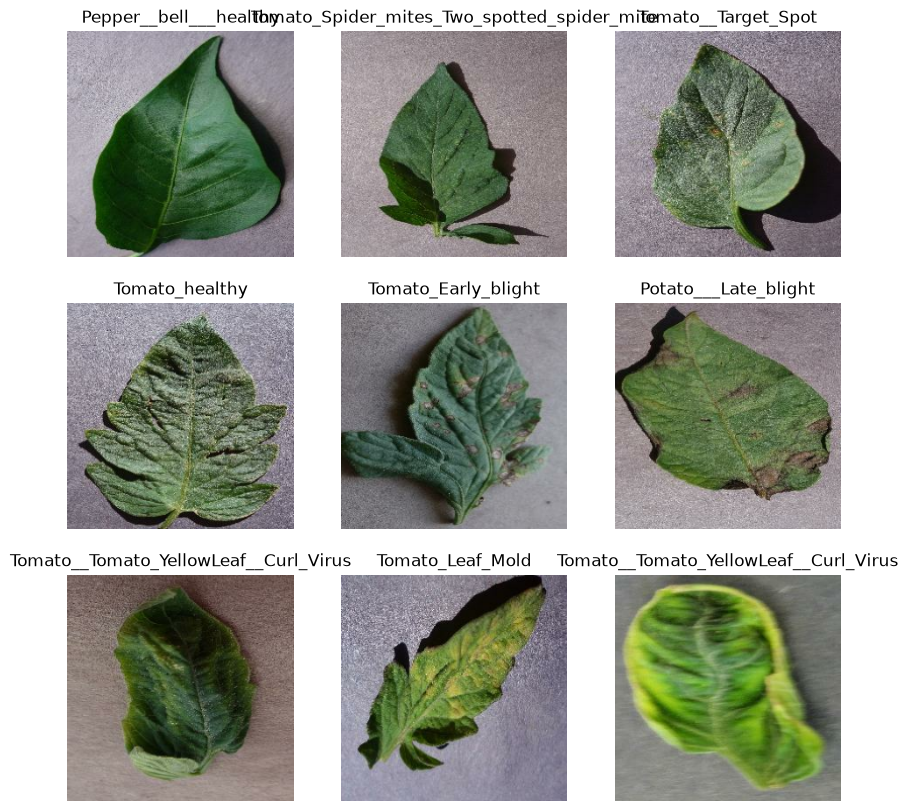

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))

for images, labels in train_dataset.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

plt.show()

In [24]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)
validation_dataset = validation_dataset.prefetch(buffer_size=AUTOTUNE)

In [25]:
model = keras.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.Rescaling(1./255),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dense(len(class_names), activation="softmax")
])

In [26]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [27]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,170,895 (42.61 MB)

 Trainable params: 11,170,895 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [28]:
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=10
)

Epoch 1/10


/home/supriyo/tf-env/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1795438557.887722   14854 service.cc:153] XLA service 0x7781dc007670 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1795438557.887784   14854 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3050 6GB Laptop GPU, Compute Capability 8.6 (Driver: 13.3.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.24.0)
I0000 00:00:1795438557.907550   14854 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1795438558.040543   14854 cuda_dnn.cc:461] Loaded cuDNN version 92400
I0000 00:00:1795438558.048866   14854 dot_merger.cc:481] M

  1/516 ━━━━━━━━━━━━━━━━━━━━ 1:10:32 8s/step - accuracy: 0.0938 - loss: 2.7144

I0000 00:00:1795438565.156169   14854 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


515/516 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.6484 - loss: 1.1074

I0000 00:00:1795438597.733092   14856 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2020__.39


516/516 ━━━━━━━━━━━━━━━━━━━━ 52s 85ms/step - accuracy: 0.6490 - loss: 1.1058 - val_accuracy: 0.7831 - val_loss: 0.6383
Epoch 2/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 34s 67ms/step - accuracy: 0.8613 - loss: 0.4176 - val_accuracy: 0.8636 - val_loss: 0.3978
Epoch 3/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 34s 67ms/step - accuracy: 0.9210 - loss: 0.2409 - val_accuracy: 0.8907 - val_loss: 0.3392
Epoch 4/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 35s 67ms/step - accuracy: 0.9512 - loss: 0.1455 - val_accuracy: 0.8818 - val_loss: 0.4046
Epoch 5/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 35s 67ms/step - accuracy: 0.9611 - loss: 0.1168 - val_accuracy: 0.9004 - val_loss: 0.3428
Epoch 6/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 35s 67ms/step - accuracy: 0.9723 - loss: 0.0826 - val_accuracy: 0.8890 - val_loss: 0.4046
Epoch 7/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 35s 67ms/step - accuracy: 0.9731 - loss: 0.0767 - val_accuracy: 0.8871 - val_loss: 0.4557
Epoch 8/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 34s 67ms/step - accuracy: 0.9805 - loss: 0.0566 - val_accurac

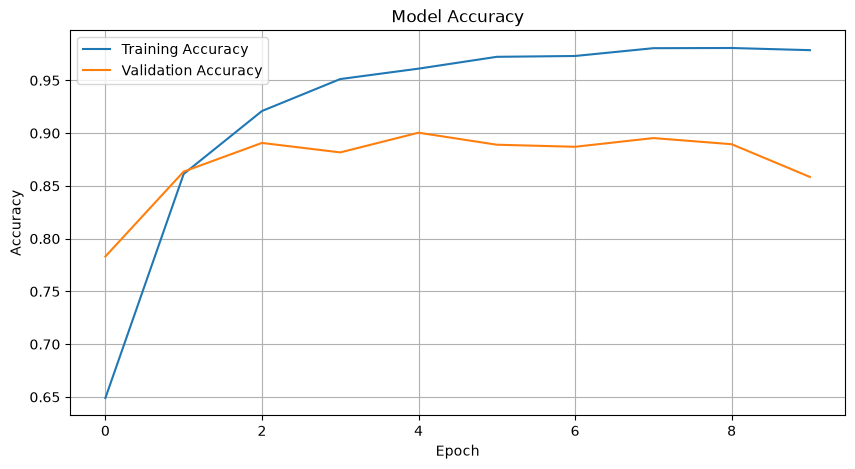

In [29]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

In [30]:
loss, accuracy = model.evaluate(validation_dataset)

print("Validation Loss:", loss)
print("Validation Accuracy:", accuracy * 100, "%")

129/129 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.8585 - loss: 0.6642
Validation Loss: 0.6641629934310913
Validation Accuracy: 85.84928512573242 %


In [37]:
import os

class_folder = os.path.join(dataset_path, "Tomato_healthy")

image_files = os.listdir(class_folder)

print("Available Images:", len(image_files))
print("First Image:", image_files[0])

Available Images: 1591
First Image: d074483d-5063-4bed-93f5-c0d798e9283c___RS_HL 0231.JPG


In [40]:
from PIL import Image
from tensorflow.keras.utils import load_img, img_to_array

print("Pillow:", Image.__version__)
print("Image loader:", load_img)

Pillow: 13.0.0
Image loader: <function load_img at 0x778314752020>


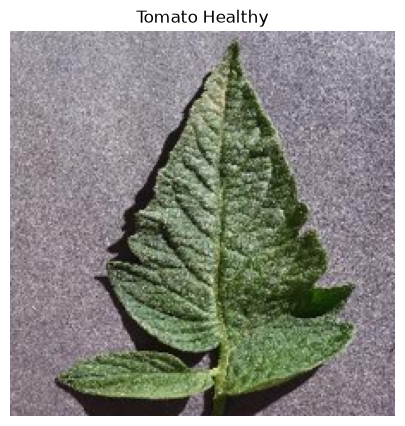

In [42]:
image_path = os.path.join(class_folder, image_files[0])

img = Image.open(image_path).convert("RGB")
img = img.resize((224, 224))

plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.title("Tomato Healthy")
plt.axis("off")
plt.show()

In [43]:
img_array = img_to_array(img)

img_array = tf.expand_dims(img_array, axis=0)

print("Input Shape:", img_array.shape)

Input Shape: (1, 224, 224, 3)


In [44]:
predictions = model.predict(img_array)

predicted_class = np.argmax(predictions[0])

predicted_disease = class_names[predicted_class]

confidence = np.max(predictions[0]) * 100

print("Predicted Disease:", predicted_disease)
print("Confidence:", round(confidence, 2), "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Predicted Disease: Tomato_healthy
Confidence: 99.73 %


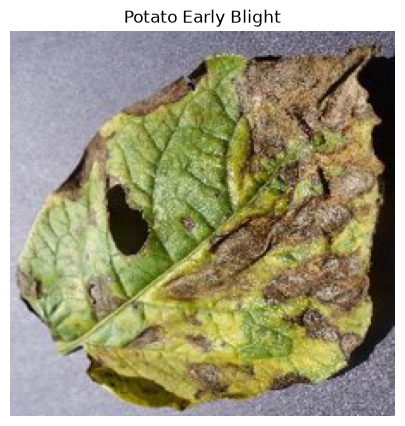

In [45]:
class_folder = os.path.join(dataset_path, "Potato___Early_blight")

image_files = os.listdir(class_folder)

image_path = os.path.join(class_folder, image_files[0])

img = Image.open(image_path).convert("RGB")
img = img.resize((224, 224))

plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.title("Potato Early Blight")
plt.axis("off")
plt.show()

In [46]:
img_array = img_to_array(img)

img_array = tf.expand_dims(img_array, axis=0)

print("Input Shape:", img_array.shape)

Input Shape: (1, 224, 224, 3)


In [47]:
predictions = model.predict(img_array)

predicted_class = np.argmax(predictions[0])

predicted_disease = class_names[predicted_class]

confidence = np.max(predictions[0]) * 100

print("Predicted Disease:", predicted_disease)
print("Confidence:", round(confidence, 2), "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
Predicted Disease: Potato___Early_blight
Confidence: 99.97 %


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 695ms/step


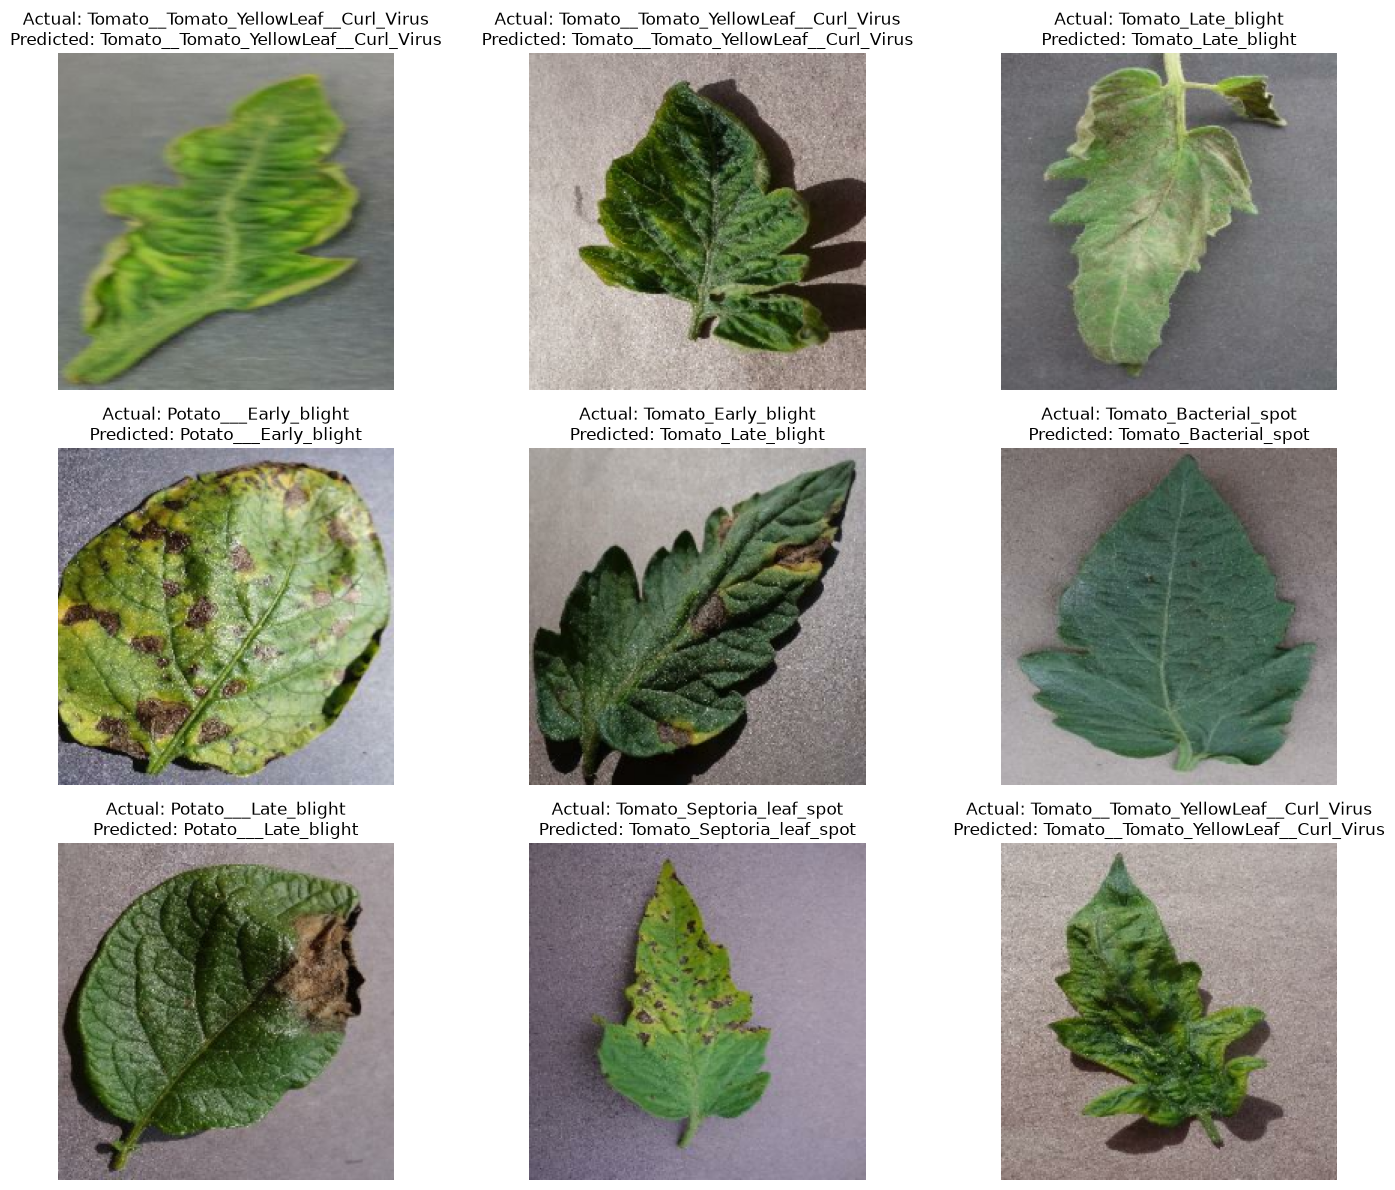

In [48]:
for images, labels in validation_dataset.take(1):
    predictions = model.predict(images)

    plt.figure(figsize=(15, 12))

    for i in range(9):
        predicted_class = np.argmax(predictions[i])
        actual_class = labels[i].numpy()

        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))

        plt.title(
            f"Actual: {class_names[actual_class]}\n"
            f"Predicted: {class_names[predicted_class]}"
        )

        plt.axis("off")

    plt.tight_layout()
    plt.show()